In [2]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# Configurar ruta raíz del proyecto
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import src.preprocessing as preprocessing
import src.config as config

print(f"Versión de TensorFlow: {tf.__version__}")
print("Módulo src.preprocessing cargado correctamente.")

Versión de TensorFlow: 2.21.0
Módulo src.preprocessing cargado correctamente.


In [4]:
split_csv = PROJECT_ROOT / "data" / "manifest_split.csv"

if split_csv.exists():
    df_split = pd.read_csv(split_csv)
    print(f"Manifest cargado exitosamente. Total de registros: {len(df_split)}")
    print("\nConteo por conjunto (split):")
    print(df_split['split'].value_counts())
else:
    print("⚠️ No se encontró data/manifest_split.csv")

df_split.head(3)

Manifest cargado exitosamente. Total de registros: 2000

Conteo por conjunto (split):
split
train    1406
val       302
test      292
Name: count, dtype: int64


,filepath,filename,label_name,label,patient_id,split
0,C:\Users\Ruben Caicedo\Desktop\Mater_en_IA_y_C...,person911_virus_1567.jpeg,PNEUMONIA,1,person911,test
1,C:\Users\Ruben Caicedo\Desktop\Mater_en_IA_y_C...,NORMAL2-IM-0924-0001.jpeg,NORMAL,0,NORMAL2-IM-0924-0001,train
2,C:\Users\Ruben Caicedo\Desktop\Mater_en_IA_y_C...,person1598_bacteria_4195.jpeg,PNEUMONIA,1,person1598,train


In [5]:
# Definición de parámetros de preprocesamiento para ResNet50
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(f"Dimensiones de entrada configuradas: {IMG_SIZE} x 3 canales (RGB)")
print(f"Tamaño de lote (Batch Size): {BATCH_SIZE}")

# Cargar un lote de muestra para verificación
df_train = df_split[df_split['split'] == 'train']
sample_paths = df_train['filepath'].head(BATCH_SIZE).tolist()

print(f"\nMuestra de rutas procesadas correctamente: {len(sample_paths)} imágenes de entrenamiento.")

Dimensiones de entrada configuradas: (224, 224) x 3 canales (RGB)
Tamaño de lote (Batch Size): 32

Muestra de rutas procesadas correctamente: 32 imágenes de entrenamiento.


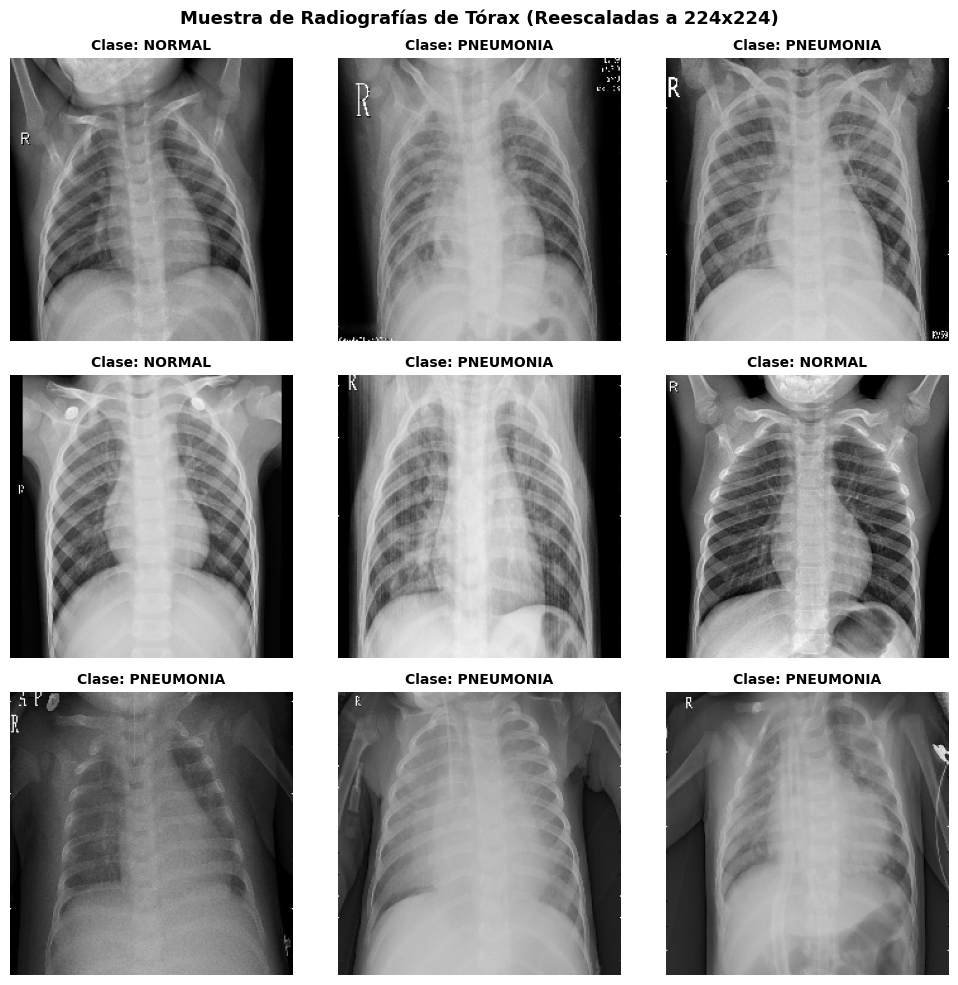

In [6]:
class_names = {0: 'NORMAL', 1: 'PNEUMONIA'}

plt.figure(figsize=(10, 10))
df_sample = df_train.head(9).reset_index(drop=True)

for i, row in df_sample.iterrows():
    ax = plt.subplot(3, 3, i + 1)
    img_path = PROJECT_ROOT / row['filepath'] if not Path(row['filepath']).is_absolute() else Path(row['filepath'])
    
    if img_path.exists():
        img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
        plt.imshow(img)
        label_text = class_names.get(row['label'], row['label_name'])
        plt.title(f"Clase: {label_text}", fontsize=10, fontweight='bold')
    else:
        plt.text(0.5, 0.5, "Imagen no encontrada", ha='center')
    
    plt.axis("off")

plt.suptitle("Muestra de Radiografías de Tórax (Reescaladas a 224x224)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()